# Preliminary analysis of BeamNetUS data on EOS using RPI/PARTOW integrated THz sensor

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib import rc
from scipy.interpolate import interp1d
from scipy.integrate import quad 
from scipy.optimize import curve_fit

### data on fiber laser test and timing 7/29 (monday)

In [2]:
# Load oscilloscope waveform data from the Monday 7/29 fiber laser coarse timing test.
# The .npy dict contains three scope channels recorded on the Tektronix:
#   wf1 = Beam Position Monitor (BPM)
#   wf2 = Schottky Detector (SD)
#   wf3 = Photodetector (PD)
# Each channel holds 200 single-shot waveforms with 1000 time samples each.
dirname='./fiberlaser/'
fname= 'CT_Monday_SDFPD_2.npy'
data= np.load(dirname+fname,allow_pickle=True).item()
data

{'note': 'Ch1:BPM, Ch2:SD, Ch3 FPD',
 'AWAVXI11:Tek1:wf3': [array([0.1328, 0.1344, 0.1352, 0.1344, 0.1328, 0.1352, 0.136 , 0.1336,
         0.1336, 0.1352, 0.1344, 0.1336, 0.1336, 0.1344, 0.1336, 0.1336,
         0.1344, 0.1344, 0.132 , 0.1344, 0.1344, 0.1344, 0.1336, 0.1336,
         0.1344, 0.136 , 0.1328, 0.132 , 0.1328, 0.1344, 0.1344, 0.1336,
         0.1352, 0.1328, 0.1328, 0.1344, 0.1336, 0.1336, 0.1344, 0.1368,
         0.1352, 0.1352, 0.1344, 0.136 , 0.1336, 0.1344, 0.1336, 0.1344,
         0.1336, 0.1368, 0.1344, 0.136 , 0.132 , 0.1352, 0.1344, 0.1352,
         0.1352, 0.1328, 0.1344, 0.1336, 0.1328, 0.1352, 0.1344, 0.136 ,
         0.1336, 0.1352, 0.1328, 0.1344, 0.132 , 0.1352, 0.1344, 0.1352,
         0.1336, 0.1336, 0.1352, 0.1352, 0.1344, 0.1344, 0.1336, 0.1344,
         0.1352, 0.1352, 0.1344, 0.1336, 0.1336, 0.1352, 0.1368, 0.1336,
         0.1352, 0.1352, 0.1352, 0.1344, 0.1344, 0.1336, 0.1344, 0.1336,
         0.1344, 0.1352, 0.1352, 0.1352, 0.1344, 0.136 , 0.1352, 0

In [3]:
# Inspect the available keys and confirm data dimensions.
# Extract the shared time axis and zero-reference it so t=0 at the start of the window.
keys = data.keys()
print(keys)
print(np.shape(data['AWAVXI11:Tek1:wf2']))  # expected (200 shots, 1000 samples)
t=np.array(data['AWAVXI11:Tek1:x'][:])
t=t-t[0]
print(len(t))

dict_keys(['note', 'AWAVXI11:Tek1:wf3', 'AWAVXI11:Tek1:wf3_ts', 'AWAVXI11:Tek1:wf2', 'AWAVXI11:Tek1:wf2_ts', 'AWAVXI11:Tek1:wf1', 'AWAVXI11:Tek1:wf1_ts', 'AWAVXI11:Tek1:x', 'AWAVXI11:Tek1:x_ts'])
(200, 1000)
200


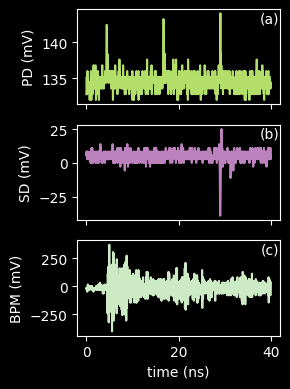

In [4]:
# Three-panel plot of a single shot showing all three detector channels vs time.
# Time axis converted from seconds to nanoseconds; amplitudes converted from V to mV.
# The shared x-axis and minimal vertical spacing reveal the temporal alignment between signals.
f, (ax1, ax2, ax3) = plt.subplots(3,1, sharex=True, figsize=(3,4))

ax1.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 1e3*data['AWAVXI11:Tek1:wf3'][0][:], 'C6')
ax2.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 1e3*data['AWAVXI11:Tek1:wf2'][0][:], 'C7')
ax3.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 1e3*data['AWAVXI11:Tek1:wf1'][0][:], 'C8')
ax3.set_xlabel('time (ns)')
ax1.set_ylabel('PD (mV)')
ax2.set_ylabel('SD (mV)')
ax3.set_ylabel('BPM (mV)')
plt.subplots_adjust(hspace=0.025)

ax1.text(0.95, 0.905,'(a)', ha='center', va='center', transform=ax1.transAxes)
ax2.text(0.95, 0.905,'(b)', ha='center', va='center', transform=ax2.transAxes)
ax3.text(0.95, 0.905,'(c)', ha='center', va='center', transform=ax3.transAxes)

plt.tight_layout()
plt.savefig('coarsetiming.png', dpi=300, bbox_inches='tight', transparent  ='true')

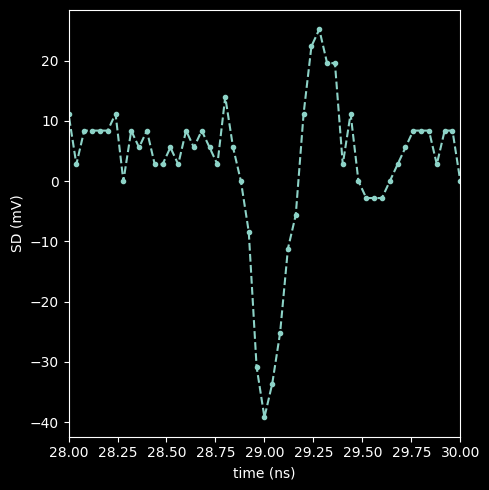

In [5]:
# Zoomed view of the SD (Schottky Detector) signal only, windowed to 28-30 ns.
# This isolates the zero-crossing region of the SD waveform, which is the most
# amplitude-sensitive region for converting a timing shift into a voltage change.
f, ax2 = plt.subplots(1,1, figsize=(5,5))
ax2.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 1e3*data['AWAVXI11:Tek1:wf2'][0][:], '.--')
ax2.set_xlabel('time (ns)')
ax2.set_ylabel('SD (mV)')
ax2.set_xlim(28,30)
plt.tight_layout()
plt.savefig('coarsetiming_SD.png', dpi=300, bbox_inches='tight', transparent  ='true')

In [6]:
# Load the July 31 coarse timing scan data.
# BPDwf shape: (101 phase steps, 4 detector channels, 5000 time samples per waveform).
# 'phase' holds the RF phase setpoint in degrees for each step; 'x' is the shared time axis.
dirname='Data_raw/July31_/'
fname= 'CoarseScan10nC_4_0.npz'
data1= np.load(dirname+fname)
keys = data1.keys()
print(keys)
print(np.shape(data1['BPDwf']))

KeysView(NpzFile 'Data_raw/July31_/CoarseScan10nC_4_0.npz' with keys: x, BPDwf, ictwf, phase)
(101, 4, 5000)


In [7]:
# Convert the RF phase setpoint (degrees) to an equivalent optical time delay (picoseconds).
# The RF oscillator runs at 81.25 MHz, so one full period = 1/81.25e6 s.
# A phase shift of N degrees corresponds to N/360 of one period.
phase= data1['phase']
phase_time_delay = phase / 81.25e6 / 360 * 1e12  # ps
print(phase_time_delay-phase_time_delay[0])  # confirm zero-referenced time delays

[  0.           3.41880342   6.83760684  10.25641026  13.67521368
  17.09401709  20.51282051  23.93162393  27.35042735  30.76923077
  34.18803419  37.60683761  41.02564103  44.44444444  47.86324786
  51.28205128  54.7008547   58.11965812  61.53846154  64.95726496
  68.37606838  71.79487179  75.21367521  78.63247863  82.05128205
  85.47008547  88.88888889  92.30769231  95.72649573  99.14529915
 102.56410256 105.98290598 109.4017094  112.82051282 116.23931624
 119.65811966 123.07692308 126.4957265  129.91452991 133.33333333
 136.75213675 140.17094017 143.58974359 147.00854701 150.42735043
 153.84615385 157.26495726 160.68376068 164.1025641  167.52136752
 170.94017094 174.35897436 177.77777778 181.1965812  184.61538462
 188.03418803 191.45299145 194.87179487 198.29059829 201.70940171
 205.12820513 208.54700855 211.96581197 215.38461538 218.8034188
 222.22222222 225.64102564 229.05982906 232.47863248 235.8974359
 239.31623932 242.73504274 246.15384615 249.57264957 252.99145299
 256.4102564

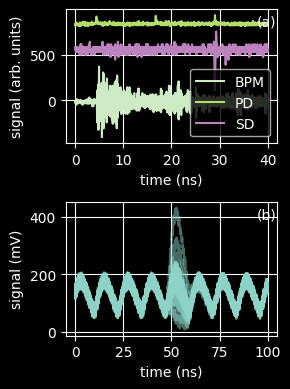

In [8]:
# Two-panel figure combining the single-shot calibration signals (top) with all BPD coarse-scan traces (bottom).
#
# Top panel (ax1): overlays BPM, PD (scaled x10 and DC-offset removed), and SD (shifted up by 500)
#   to show the temporal relationship between the beam pickup and the THz sensor signals.
#
# Bottom panel (ax2): all 101 BPD waveforms (channel index 2) from the phase scan, plotted with
#   50% transparency so shot-to-shot variation is visible as a spread band.
f, (ax1, ax2) = plt.subplots(2,1, figsize=(3,4))

ax1.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 1e3*data['AWAVXI11:Tek1:wf1'][0][:], 'C8', label='BPM')
ax1.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 1e4*(data['AWAVXI11:Tek1:wf3'][0][:]-0.051), 'C6', label='PD')
ax1.plot(data['AWAVXI11:Tek1:x'][0][:]*1e9, 500+1e4*data['AWAVXI11:Tek1:wf2'][0][:], 'C7', label='SD')
ax1.legend(loc='lower right')
ax1.set_xlabel('time (ns)')
ax1.set_ylabel('signal (arb. units)')
ax1.grid()

ax2.set_xlabel('time (ns)')
ax2.set_ylabel('signal (mV)')
for i in range(0, data1['BPDwf'].shape[0]):
    ax2.plot(1e9*data1['x'][0,:], 1e3*data1['BPDwf'][i,2,:], label='BPDwf', alpha=0.5, color='C0')
ax2.grid()

ax1.text(0.95, 0.905,'(a)', ha='center', va='center', transform=ax1.transAxes)
ax2.text(0.95, 0.905,'(b)', ha='center', va='center', transform=ax2.transAxes)

plt.tight_layout()
plt.savefig('timingandscan.png', dpi=300, bbox_inches='tight', transparent  ='true')

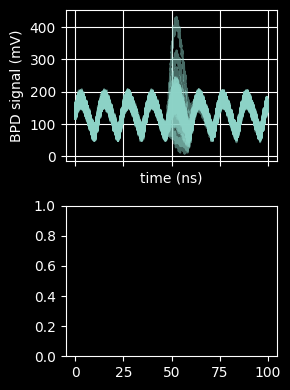

In [9]:
# Two-panel summary figure for the coarse BPD phase scan.
#
# Panel (a): all 101 BPD waveform traces overlaid — shows the spread in amplitude across scan steps.
# Panel (b): 2D heatmap (imshow) with the waveform time on x and the equivalent optical delay
#   (converted from RF phase) on y. The color encodes BPD signal amplitude in mV.
#   This view makes the sliding of the THz pulse peak across the time window clearly visible.
#
# The colorbar is placed as a small inset inside panel (b) to avoid wasting figure space.
f, (ax1, ax2) = plt.subplots(2,1, figsize=(3,4), sharex=True)

for i in range(0, data1['BPDwf'].shape[0]):
    ax1.plot(1e9*data1['x'][0,:], 1e3*data1['BPDwf'][i,2,:], label='BPDwf', alpha=0.5, color='C0')
ax1.set_xlabel('time (ns)')
ax1.set_ylabel('BPD signal (mV)')
ax1.grid()

# y-axis extent runs from 0 to the total delay range spanned by the phase scan
im = ax2.imshow(1e3*data1['BPDwf'][:,2,:], aspect='auto',
                extent=[1e9*data1['x'][0,0], 1e9*data1['x'][0,-1],
                        0, phase_time_delay[-1]-phase_time_delay[0]],
                origin='lower', cmap='jet')
ax2.set_xlabel('time (ns)')
ax2.set_ylabel('delay (ps)')

ax1.text(0.95, 0.905,'(a)', ha='center', va='center', transform=ax1.transAxes)
ax2.text(0.95, 0.905,'(b)', ha='center', va='center', transform=ax2.transAxes)

# Inset colorbar: [x0, y0, width, height] in axes-fraction coordinates
cbar_ax = ax2.inset_axes([0.1, 0.4, 0.3, 0.1])
cbar = plt.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('BPD signal (mV)')

plt.tight_layout()
plt.savefig('BPDwf_combined.png', dpi=300, bbox_inches='tight', transparent  ='true')

### check data from July30th to plot a few traces


In [10]:
dirname='Data_raw/July30_/'
fname= 'fiber_test_0730_CTRscrnOut.npz'
data= np.load(dirname+fname)
data

NpzFile 'Data_raw/July30_/fiber_test_0730_CTRscrnOut.npz' with keys: x, BPDwf, phase

(601, 4, 5000)
(1, 5000)
[ 56.35874229 105.97624122   0.12558783]


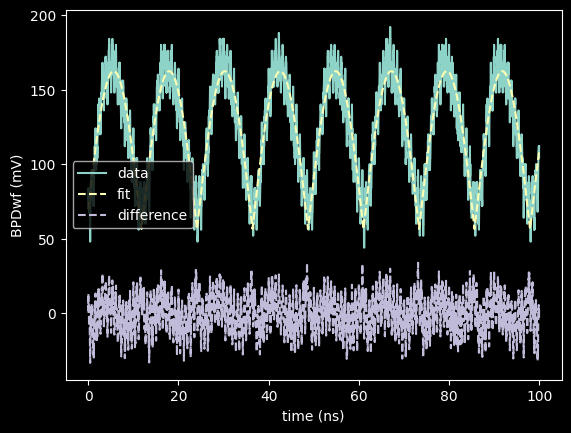

In [11]:
print(np.shape(data['BPDwf']))
print(np.shape(data['x']))
mV=1e3
t= 1e9*data['x'][0,:]
plt.plot (t,data['BPDwf'][0,2,:]*mV, label='data')
# fit a+b*abs(sin(2*pi*f*t+phi)) to the data
def fit_func(t, a, b, phi):
    f = 81.25e6*1e-9*0.5
    return a + b * np.abs(np.sin(2 * np.pi * f * t + phi))
# fit the data
popt, pcov = curve_fit(fit_func, t, data['BPDwf'][0,2,:]*mV, p0=[100, 50, 1])
# plot the fit
print(popt)
plt.plot(t, fit_func(t, *popt), label='fit', linestyle='--')
plt.plot(t, data['BPDwf'][0,2,:]*mV-fit_func(t, *popt), label='difference', linestyle='--')
plt.xlabel('time (ns)')
plt.ylabel('BPDwf (mV)')
plt.legend()


[ 61.54785801 109.87299607   0.66998226]
[ 62.12819321 109.35351229   0.67083796]
[ 62.25423114 108.43700803   0.67298313]
[ 61.35474728 108.52939116   0.67943944]
[ 61.08217131 109.04896149   0.68318523]
[ 61.37941417 110.79226187   0.67503391]
[ 62.6455271  110.23900401   0.67350879]
[ 62.22301567 112.01802978   0.68098018]
[ 62.23807781 108.81213546   0.68330235]
[ 61.87659155 108.60635389   0.68339084]
[ 61.79466691 109.38417065   0.68080847]
[ 61.79442909 109.36549175   0.68545035]
[ 62.69385949 110.66367274   0.67691572]
[ 62.43664816 110.42620683   0.68656894]
[ 62.52080492 107.61652296   0.69091892]
[ 61.72777837 108.61655167   0.68859029]
[ 61.95655551 109.92234234   0.6838326 ]
[ 62.27924921 110.20377948   0.6882891 ]
[ 62.52117532 109.66280126   0.6886248 ]
[ 62.13292117 108.79342039   0.68736461]
[ 61.94323024 109.71628643   0.68917694]
[ 61.42458317 110.30884059   0.69840377]
[ 61.46720982 109.67888379   0.69513171]
[ 61.90473314 107.18503235   0.70143283]
[ 61.28774295 11

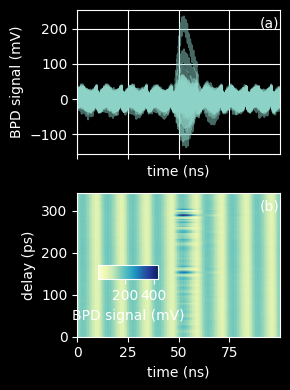

In [12]:
#combine the plot from ax2 above and the image plot into one figure
f, (ax1, ax2) = plt.subplots(2,1, figsize=(3,4), sharex=True)    
# have the same x axis for the two plots    
for i in range(0, data1['BPDwf'].shape[0]):
    popt, pcov = curve_fit(fit_func, t, data1['BPDwf'][i,2,:]*mV, p0=[100, 50, 1])
    print(popt)
    ax1.plot(1e9*data1['x'][0,:], 1e3*data1['BPDwf'][i,2,:]-fit_func(t, *popt), label='BPDwf', alpha=0.5, color='C0')
ax1.set_xlabel('time (ns)')
ax1.set_ylabel('BPD signal (mV)')
ax1.grid()
im = ax2.imshow(1e3*data1['BPDwf'][:,2,:], aspect='auto', extent=[1e9*data1['x'][0,0], 1e9*data1['x'][0,-1], 0, phase_time_delay[-1]-phase_time_delay[0]], origin='lower', cmap='YlGnBu')
ax2.set_xlabel('time (ns)')
ax2.set_ylabel('delay (ps)')
ax1.text(0.95, 0.905,'(a)', ha='center', va='center', transform=ax1.transAxes)
ax2.text(0.95, 0.905,'(b)', ha='center', va='center', transform=ax2.transAxes)

# add color bar horizontalky within ax2
# scale the color bar to fit within ax2 reduce the size of the color bar
# add a colorbar to ax2 within the plot and make sure its scale is within 0.3 of the ax2 width
cbar_ax = ax2.inset_axes([0.1, 0.4, 0.3, 0.1])  # [x0, y0, width, height]  
cbar = plt.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('BPD signal (mV)')


#cbar = plt.colorbar(im, ax=ax2)
#cbar.set_label('BPD signal (mV)')
# share the same x axis
plt.tight_layout()

### jitter data analysis (data of 7/30)

In [13]:
rstfine=np.load("Data_raw/July31_/scan_coarse_573p8-578_0p025_CTR_2025_7_31_10_46.npy",allow_pickle=True).item()
jitterstat=np.load("Data_raw/July31_/jitter_0Xing_2025_7_31_11_5.npy",allow_pickle=True).item()
print(rstfine.keys())
print(jitterstat.keys())

lengths = [len(row) for row in rstfine['peak']]
print(set(lengths))  
print(min(lengths), max(lengths))
print(lengths)


dict_keys(['peak', 'peak_pos', 'valley', 'valley_pos', 'phase'])
dict_keys(['peak', 'peak_pos', 'valley', 'valley_pos', 'phase'])
{8, 9}
8 9
[8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 8, 8, 8, 8, 8, 8, 9, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 

In [14]:
#print(np.shape(fine['phase']))
#print(fine['peak'])
# convert fine['peak'] to numpy array

fpeak2=[]
fpeak1=[]
indx=5
fine_pht=np.array(rstfine['phase'])/81.25e6/360*1e12
fine_ph=fine_pht-fine_pht[0]
fine_peak=rstfine['peak']

for i in range(len(fine_ph)):
    fpeak2.append(fine_peak[i][indx])
    fpeak1.append(fine_peak[i][indx-1])
fpeak1=np.array(fpeak1)
fpeak2=np.array(fpeak2)
AmplJitter=np.zeros(len(fine_ph))
for i in range(len(fine_ph)):
    AmplJitter[i]=fine_peak[i][indx-1]


#rint (stat_ph) 

total 1352
sd 0.7615185205490583
96.44400905932925 0.7615185205490583


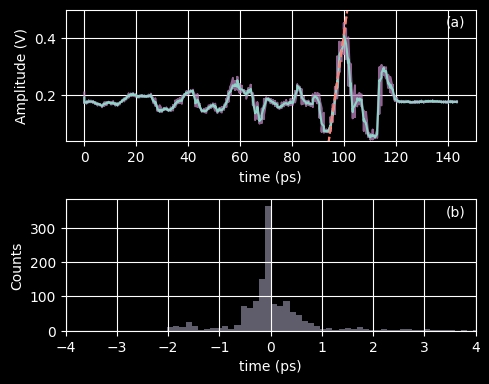

In [15]:
F, (ax1, ax2) = plt.subplots(2,1, figsize=(5,4))


fpeak1_avg = np.array([np.mean(fpeak1[i:i+4]) for i in range(0, len(fpeak1), 4)])
fphase_avg = np.array([np.mean(fine_ph[i:i+4]) for i in range(0, len(fine_ph), 4)])

# do a polyfit on fpeak1_avg for value of fine_ph[::4] between 95 and 100
mask = (fine_ph[::4] > 95) & (fine_ph[::4] < 100)
coeffs = np.polyfit(fine_ph[::4][mask], fpeak1_avg[mask], 1)
fpeak1_fit = np.polyval(coeffs, fine_ph[::4])       
fpeak1_fit = np.polyval(coeffs, fine_ph[::4])
ax1.set_ylim(0.04,0.5)
#ax1.set_xlim(80, 120)
fpeak2_avg = np.array([np.mean(fpeak2[i:i+4]) for i in range(0, len(fpeak2), 4)])
ax1.plot(fine_ph,fpeak1,'C7', alpha=0.76, label='fpeak1')
ax1.plot(fine_ph[::4], fpeak1_fit, 'C3--', label='fpeak1 fit')
ax1.plot(fine_ph[::4],fpeak1_avg,'C0')
ax1.plot(fine_ph[::4], fpeak1_fit, 'C3--', label='fpeak1 fit')
ax1.set_xlabel('time (ps)')
ax1.set_ylabel('Amplitude (V)')
ax1.grid()

#AmplJitter= AmplJitter-96.54515510109754
# convert to ps 

coeffsInverse = np.polyfit(fpeak1_avg[mask], fine_ph[::4][mask], 1)
ax1.set_xlabel('time (ps)')
# Gaussian fie of the histogram
def gaussian(x, mu, sigma):
    return 1/(sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
# Fit the histogram with a Gaussian
mu, sigma = np.mean(np.polyval(coeffsInverse, AmplJitter)), np.std(np.polyval(coeffsInverse, AmplJitter))
x_fit = np.linspace(np.min(np.polyval(coeffsInverse, AmplJitter)), np.max(np.polyval(coeffsInverse, AmplJitter)), 100)
y_fit = gaussian(x_fit, mu, sigma)
ax2.set_xlabel('time (ps)')
ax2.set_ylabel('Counts')
print ('total', len(AmplJitter))
ax2.hist(np.polyval(coeffsInverse, AmplJitter)-mu, bins=51, label='stat_peak', color='C2', alpha=0.5)    
#ax2.plot(x_fit-mu, y_fit, 'C3--', label='Gaussian fit')
#print standard deviation on plot np.std(np.polyval(coeffsInverse, AmplJitter))
print ('sd', np.std(np.polyval(coeffsInverse, AmplJitter)))

ax2.set_xlim(-4, 4)
print (mu, sigma)
ax1.text(0.95, 0.905,'(a)', ha='center', va='center', transform=ax1.transAxes)
ax2.text(0.95, 0.905,'(b)', ha='center', va='center', transform=ax2.transAxes)
ax2.grid()
plt.tight_layout()
plt.savefig('jitter.png', dpi=300, bbox_inches='tight', transparent  ='true')

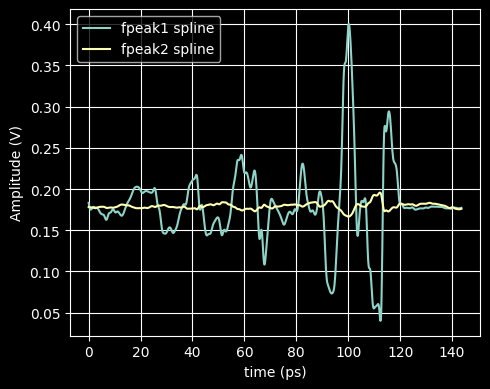

In [16]:
# do a cubic spline interpolation of fine_ph[::4], fpeak1_avg and fine_ph[::4], fpeak2_avg
# (interp1d was already imported earlier in the notebook)

# compute 4-sample averages (these variables already exist elsewhere in the notebook,
# but recomputing here ensures consistent lengths)
fpeak1_avg = np.array([np.mean(fpeak1[i:i+4]) for i in range(0, len(fpeak1), 4)])
fpeak2_avg = np.array([np.mean(fpeak2[i:i+4]) for i in range(0, len(fpeak2), 4)])
fphase_avg = np.array([np.mean(fine_ph[i:i+4]) for i in range(0, len(fine_ph), 4)])

# align lengths in case of off-by-one differences
minlen = min(len(fphase_avg), len(fpeak1_avg), len(fpeak2_avg))
fphase_arr = fphase_avg[:minlen]
y1 = fpeak1_avg[:minlen]
y2 = fpeak2_avg[:minlen]

# remove non-finite entries
mask = np.isfinite(fphase_arr) & np.isfinite(y1) & np.isfinite(y2)
fphase_arr = fphase_arr[mask]
y1 = y1[mask]
y2 = y2[mask]

# combine duplicate x-values by averaging y for identical x (np.unique sorts x)
ux, inv = np.unique(fphase_arr, return_inverse=True)
y1_mean = np.array([y1[inv == i].mean() for i in range(len(ux))])
y2_mean = np.array([y2[inv == i].mean() for i in range(len(ux))])

# need at least 4 unique points for cubic interpolation
if len(ux) < 4:
	raise ValueError("Not enough unique points for cubic interpolation")

# build splines (allow extrapolation)
fpeak1_spline = interp1d(ux, y1_mean, kind='cubic', fill_value='extrapolate', assume_sorted=True)
fpeak2_spline = interp1d(ux, y2_mean, kind='cubic', fill_value='extrapolate', assume_sorted=True)

# plot the spline interpolation over a dense grid spanning the averaged phase range
phase_grid = np.linspace(ux[0], ux[-1], 1000)
f, ax = plt.subplots(1,1, figsize=(5,4))
ax.plot(phase_grid, fpeak1_spline(phase_grid), 'C0', label='fpeak1 spline')
ax.plot(phase_grid, fpeak2_spline(phase_grid), 'C1', label='fpeak2 spline')
ax.set_xlabel('time (ps)')
ax.set_ylabel('Amplitude (V)')
ax.grid()
ax.legend()
plt.tight_layout()


In [17]:
print (fine_ph[1:30])


[0.         0.         0.         0.         0.         0.
 0.         0.85470085 0.85470085 0.85470085 0.85470085 0.85470085
 0.85470085 0.85470085 0.85470085 1.70940171 1.70940171 1.70940171
 1.70940171 1.70940171 1.70940171 1.70940171 1.70940171 2.56410256
 2.56410256 2.56410256 2.56410256 2.56410256 2.56410256]
